Saving digits.csv to digits (6).csv
   0  0.1   5  13   9   1  4  8  0.2  2
0  1    1  16  11   3  16  0  0    1  0
1  2    2  16   3   1   5  9  0    2  3
2  3    3   4  13  12   1  0  1    3  0
3  4    4   3   2  16  13  4  6    4  0
4  5    5   4  16  16   4  0  7    5  0
Dataset shape: (1796, 10)
Explained variance:
[ 3.46573083e-01  2.10871593e-01  1.51488930e-01  1.07209902e-01
  7.25038528e-02  6.80520862e-02  4.33005535e-02  3.11707128e-17
 -1.27039633e-17]


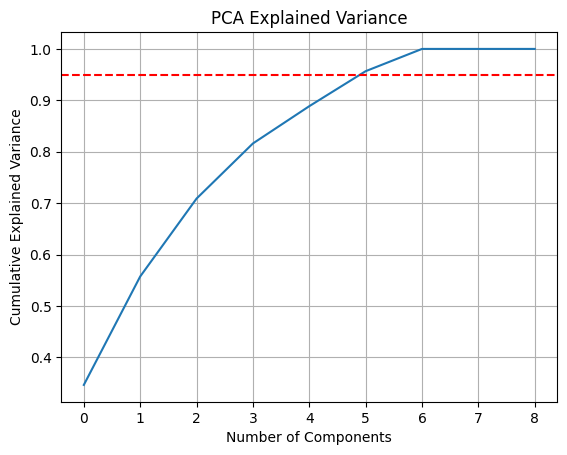

Components selected: 6


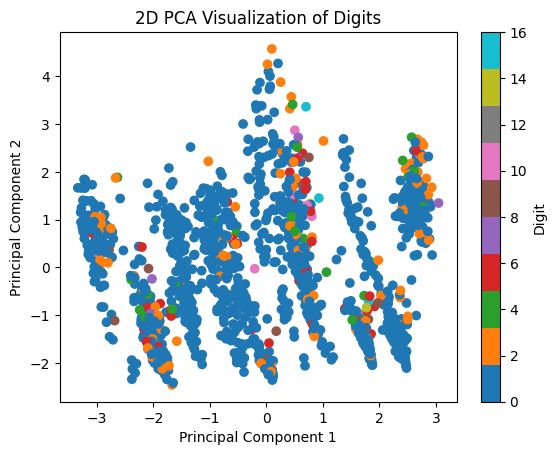

Accuracy on original data: 77.22222222222223 %
Accuracy on PCA data: 77.22222222222223 %


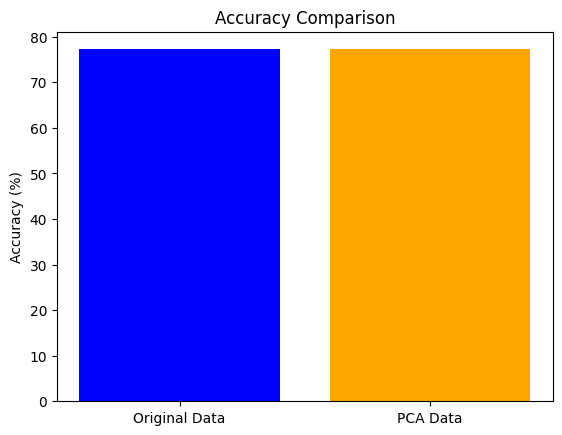

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# 1. Load dataset
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("digits.csv")

print(df.head())
print("Dataset shape:", df.shape)

# 2. Separate features and labels
# Assumption: Last column contains digit labels
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Standardize data
mean = np.sum(X_train, axis=0) / len(X_train)

variance = np.sum((X_train - mean) ** 2, axis=0) / len(X_train)

std = np.sqrt(variance)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# 5. Calculate covariance matrix
covariance = (X_train.T @ X_train) / (len(X_train) - 1)

# 6. Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(covariance)

# Arrange in descending order
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# 7. Calculate explained variance
total = np.sum(eigenvalues)
explained_variance = eigenvalues / total

cumulative_variance = np.cumsum(explained_variance)

print("Explained variance:")
print(explained_variance)

# 8. Plot explained variance
plt.plot(cumulative_variance)
plt.axhline(y=0.95, color="red", linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()

# 9. Select components retaining 95% variance
k = 0

while cumulative_variance[k] < 0.95:
    k = k + 1

k = k + 1

print("Components selected:", k)

# 10. Reduce dimensions using PCA
components = eigenvectors[:, :k]

X_train_pca = X_train @ components
X_test_pca = X_test @ components

# 11. Visualize data using first two components
X_2d = X_train @ eigenvectors[:, :2]

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="tab10")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Visualization of Digits")
plt.colorbar(label="Digit")
plt.show()

# 12. Train model on original data
model1 = LogisticRegression(max_iter=2000)
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

correct1 = 0
for i in range(len(y_test)):
    if pred1[i] == y_test[i]:
        correct1 += 1

accuracy1 = correct1 / len(y_test) * 100

# 13. Train model on PCA data
model2 = LogisticRegression(max_iter=2000)
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)

correct2 = 0
for i in range(len(y_test)):
    if pred2[i] == y_test[i]:
        correct2 += 1

accuracy2 = correct2 / len(y_test) * 100

# 14. Display accuracy comparison
print("Accuracy on original data:", accuracy1, "%")
print("Accuracy on PCA data:", accuracy2, "%")

plt.bar(
    ["Original Data", "PCA Data"],
    [accuracy1, accuracy2],
    color=["blue", "orange"]
)
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")
plt.show()
